In [ ]:
# 1. Mount your Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Install the required libraries
!pip install -q ultralytics grad-cam transformers openai plotly pydicom

# 3. Unzip the code we uploaded
!unzip -q capstone_pipeline.zip -d /content/

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 99.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 9.1 MB/s eta 0:00:00


In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

# Your new Gemini API Key
os.environ["GEMINI_API_KEY"] = "AQ.Ab8RN6KU0LYb7VETy8fA86yDioduJ5jbd8ae4o6Ifjn0rD4MlQ"

from modules.classifier import PCSADiagnosticEngine
from modules.segmenter import YOLOSurgicalSpecialist
from modules.llm_copilot import LLMCopilot, CLINICAL_PRESETS
from modules.visualization import MeshExporter

# 1. Initialize Engines (This will automatically grab your weights from Drive)
classifier = PCSADiagnosticEngine()
segmenter = YOLOSurgicalSpecialist(mode="specialist")

# We set the copilot to use Google Gemini!
copilot = LLMCopilot(use_llm=True, api_provider="gemini")

# 2. Pick a test image from your drive to analyze
test_image_path = "/content/drive/MyDrive/Capstone_Kidney_Project/misclassified_cases/Cyst- (1576).jpg"

print("\n[1/3] Running AI Vision Diagnostics...")
vision_results = classifier.analyze_scan(test_image_path)
seg_data = segmenter.run_segmentation(test_image_path, vision_results['diagnosis'])
vision_results.update(seg_data)

# 3. Generate 3D Model
print("\n[2/3] Rendering 3D Surgical Geometry...")
fig = MeshExporter.generate_3d_plotly(seg_data, vision_results['diagnosis'])
if fig:
    fig.show()

# 4. Generate LLM Clinical Report
print("\n[3/3] Generating AI Medical Report...")
patient_notes = CLINICAL_PRESETS["Case A (Severe RCC)"]
report = copilot.generate_multimodal_report(patient_notes, vision_results)

print("\n" + "="*60)
print("📝 FINAL MULTIMODAL CLINICAL REPORT (Powered by Gemini)")
print("="*60)
print(report['report_text'])

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


/usr/local/lib/python3.13/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


✅ PCSA-KidneyNeXt Weights Loaded Successfully.
🔪 Loading YOLO Surgical Segmenters...
✅ YOLO Segmenters (specialist) Loaded Successfully.
🏥 Initializing the Multimodal AI Clinical Copilot (Provider: gemini)...


config.json:   0%|          | 0.00/5.00k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  266MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]


[1/3] Running AI Vision Diagnostics...

[2/3] Rendering 3D Surgical Geometry...

[3/3] Generating AI Medical Report...
🌐 Sending Multimodal Payload to Google Gemini API...


⚠️ Gemini API Error: 404 POST https://generativelanguage.googleapis.com/v1beta/models/gemini-1.5-flash:generateContent?%24alt=json%3Benum-encoding%3Dint: models/gemini-1.5-flash is not found for API version v1beta, or is not supported for generateContent. Call ModelService.ListModels to see the list of available models and their supported methods.
🔄 Falling back to Local Rule-Based Medical Engine...

📝 FINAL MULTIMODAL CLINICAL REPORT (Powered by Gemini)
### 1. Executive Diagnostic Synthesis
The patient's CT scan indicates a **Stone** with a confidence of 66.0%. 

### 2. Pre-Operative Surgical Risk Stratification
**Protocol Recommendation:** No significant mass requiring surgical excision detected.
- ⚠️ **Risk Factor:** Diabetes detected. Monitor perioperative glycemic control and hold Metformin if IV contrast is used.
- ⚠️ **Risk Factor:** Hypertension detected. Manage blood pressure during anesthesia.


### 3. Comorbidity-Aware Renal Nutrition Plan
- **Diabetic-Renal Diet**: Strict g

⏳ Initializing AI Engines...
✅ PCSA-KidneyNeXt Weights Loaded Successfully.
🔪 Loading YOLO Surgical Segmenters...
✅ YOLO Segmenters (specialist) Loaded Successfully.
🏥 Initializing the Multimodal AI Clinical Copilot (Provider: gemini)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


🔍 RUNNING DIAGNOSTICS & SURGICAL SIZING
➡️ Primary Diagnosis: Stone (Confidence: 65.96%)


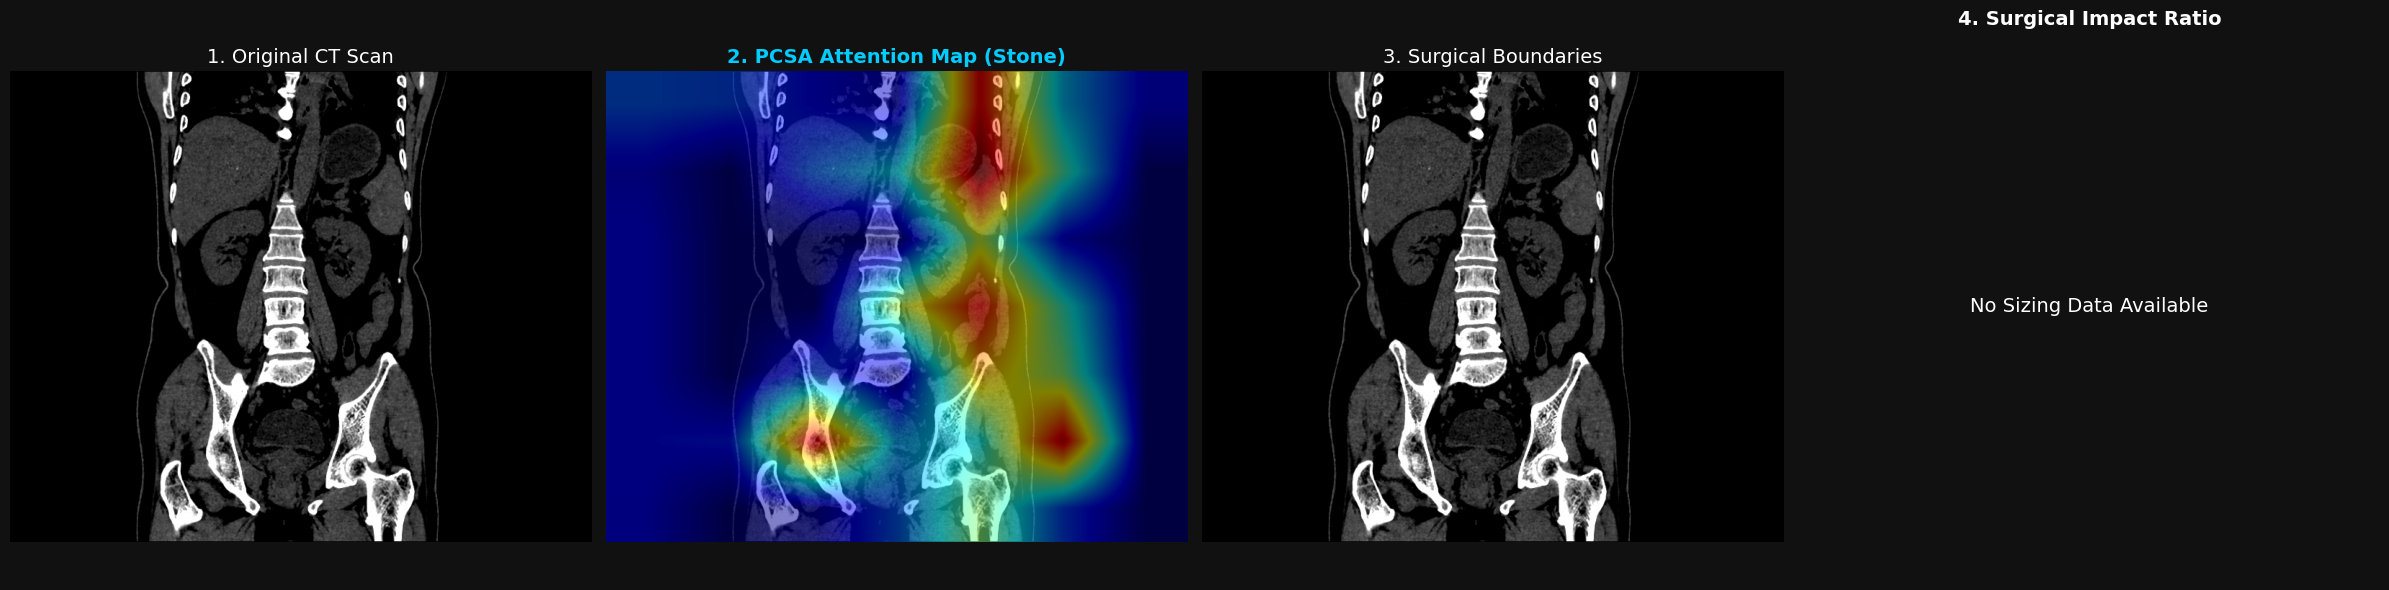


🧊 MODULE 3: 3D SURGICAL RECONSTRUCTION

📝 MODULE 4: GEMINI MULTIMODAL MEDICAL REPORT
Patient Notes Ingested:
'Patient is a 55-year-old female presenting with gross hematuria and right-sided flank pain. History of type 2 diabetes managed with Metformin, and hypertension managed with Lisinopril.'

🌐 Sending Multimodal Payload to Google Gemini API...
⚠️ Gemini API Error: 404 POST https://generativelanguage.googleapis.com/v1beta/models/gemini-1.5-flash:generateContent?%24alt=json%3Benum-encoding%3Dint: models/gemini-1.5-flash is not found for API version v1beta, or is not supported for generateContent. Call ModelService.ListModels to see the list of available models and their supported methods.
🔄 Falling back to Local Rule-Based Medical Engine...
### 1. Executive Diagnostic Synthesis
The patient's CT scan indicates a **Stone** with a confidence of 66.0%. 

### 2. Pre-Operative Surgical Risk Stratification
**Protocol Recommendation:** No significant mass requiring surgical excision detecte

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Your Gemini API Key
os.environ["GEMINI_API_KEY"] = "AQ.Ab8RN6KU0LYb7VETy8fA86yDioduJ5jbd8ae4o6Ifjn0rD4MlQ"

from modules.classifier import PCSADiagnosticEngine
from modules.segmenter import YOLOSurgicalSpecialist
from modules.llm_copilot import LLMCopilot, CLINICAL_PRESETS
from modules.visualization import MeshExporter

# 1. Initialize Engines
print("⏳ Initializing AI Engines...")
classifier = PCSADiagnosticEngine()
segmenter = YOLOSurgicalSpecialist(mode="specialist")
copilot = LLMCopilot(use_llm=True, api_provider="gemini")

# 2. Pick a test image
test_image_path = "/content/drive/MyDrive/Capstone_Kidney_Project/misclassified_cases/Cyst- (1576).jpg"

# ==========================================
# MODULE 1 & 2: PCSA VISION & YOLO SIZING
# ==========================================
print("\n" + "="*50)
print("🔍 RUNNING DIAGNOSTICS & SURGICAL SIZING")
print("="*50)

vision_results = classifier.analyze_scan(test_image_path)
diagnosis = vision_results['diagnosis']
seg_data = segmenter.run_segmentation(test_image_path, diagnosis)
vision_results.update(seg_data)

print(f"➡️ Primary Diagnosis: {diagnosis} (Confidence: {vision_results['confidence']*100:.2f}%)")

if seg_data['consumption_ratio'] > 0:
    print(f"➡️ Healthy Kidney Area: {seg_data['kidney_area']:,.0f} px²")
    print(f"➡️ Pathology Area:      {seg_data['pathology_area']:,.0f} px²")
    print(f"➡️ Severity Ratio:      {seg_data['consumption_ratio']:.2f}%")
    print(f"➡️ Protocol Rec.:       {seg_data['recommendation']}")

# ==========================================
# FULL 1x4 CAPSTONE DASHBOARD
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(24, 6))
fig.patch.set_facecolor('#111111') # Dark mode background

title_color = '#ff3333' if diagnosis == 'Tumor' else '#00ff00' if diagnosis == 'Cyst' else '#00ccff'
plot_color = title_color

# 1. Original Image
axes[0].imshow(vision_results['original_image']);
axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')

# 2. PCSA Grad-CAM Attention
axes[1].imshow(vision_results['cam_image']);
axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')

# 3. YOLO Boundaries
if seg_data['annotated_image'] is not None:
    axes[2].imshow(seg_data['annotated_image'])
else:
    axes[2].imshow(vision_results['original_image'])
axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')

# 4. Donut Chart
axes[3].set_title("4. Surgical Impact Ratio", color='white', fontsize=14, weight='bold')
if seg_data['consumption_ratio'] > 0:
    sizes = [seg_data['kidney_area'], seg_data['pathology_area']]
    labels = ['Healthy Kidney', diagnosis]
    colors = ['#00ccff', plot_color]

    wedges, texts, autotexts = axes[3].pie(
        sizes, labels=labels, colors=colors, autopct='%1.1f%%',
        startangle=90, textprops=dict(color="w", weight="bold"),
        wedgeprops=dict(width=0.4, edgecolor='#111111')
    )

    axes[3].text(0, -1.3, f"⚠️ Alert: Mass is {seg_data['consumption_ratio']:.1f}% size of kidney", color='white', ha='center', fontsize=12)
    axes[3].text(0, -1.5, seg_data['recommendation'], color=plot_color, ha='center', fontsize=12, weight='bold')
else:
    axes[3].text(0.5, 0.5, "No Sizing Data Available", color='white', ha='center', va='center', fontsize=14)
    axes[3].axis('off')

plt.tight_layout()
plt.show()

# ==========================================
# MODULE 3: PLOTLY 3D RECONSTRUCTION
# ==========================================
print("\n" + "="*50)
print("🧊 MODULE 3: 3D SURGICAL RECONSTRUCTION")
print("="*50)
fig_3d = MeshExporter.generate_3d_plotly(seg_data, diagnosis)
if fig_3d:
    fig_3d.show()

# ==========================================
# MODULE 4: MULTIMODAL LLM MEDICAL SCRIBE
# ==========================================
print("\n" + "="*50)
print("📝 MODULE 4: GEMINI MULTIMODAL MEDICAL REPORT")
print("="*50)
patient_notes = CLINICAL_PRESETS["Case A (Severe RCC)"]
print(f"Patient Notes Ingested:\n'{patient_notes}'\n")

report = copilot.generate_multimodal_report(patient_notes, vision_results)

print(report['report_text'])